<a href="https://colab.research.google.com/github/mahendiraprasathk2024lcse-hue/DataScienceDay1/blob/main/Question8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Hospital Resource Allocation Analysis

This notebook aims to analyze hospital resource allocation based on department-wise patient volume, treatment duration, staff count, and equipment utilization. We will perform data cleaning, exploratory data analysis, and build a Random Forest model to provide data-backed insights and recommendations.

### 1. Data Loading

In [1]:
import pandas as pd

# Load the dataset. Please ensure the CSV file is uploaded to the Colab environment
# and update the file path if necessary.
# Example: df = pd.read_csv('hospital_data.csv')
try:
    df = pd.read_csv('/tmp/hospital_data.csv')
    print("Data loaded successfully.")
    display(df.head())
except FileNotFoundError:
    print("Error: 'hospital_data.csv' not found. Please upload the file or update the path.")
    print("Assuming a dummy dataframe for demonstration purposes if the file is not available.")
    # Create a dummy DataFrame if the file is not found, to allow subsequent steps to run without error
    data = {
        'Month': pd.to_datetime(['2022-01-01', '2022-01-01', '2022-02-01', '2022-02-01']),
        'Department': ['Cardiology', 'Neurology', 'Cardiology', 'Neurology'],
        'Patient_Volume': [100, 70, 110, 75],
        'Average_Treatment_Duration': [5, 7, 5, 8],
        'Staff_Count': [20, 15, 21, 16],
        'Equipment_Utilisation': [0.85, 0.70, 0.88, 0.72]
    }
    df = pd.DataFrame(data)
    display(df.head())


Error: 'hospital_data.csv' not found. Please upload the file or update the path.
Assuming a dummy dataframe for demonstration purposes if the file is not available.


,Month,Department,Patient_Volume,Average_Treatment_Duration,Staff_Count,Equipment_Utilisation
0,2022-01-01,Cardiology,100,5,20,0.85
1,2022-01-01,Neurology,70,7,15,0.70
2,2022-02-01,Cardiology,110,5,21,0.88
3,2022-02-01,Neurology,75,8,16,0.72


### 2. Data Cleaning and Validation

Since the original `hospital_data.csv` was not found, we will proceed with a dummy dataset for demonstration. The initial steps involve inspecting the data types, converting 'Month' to datetime objects, and checking for missing values.

In [2]:
print("DataFrame Info:")
df.info()

print("\nChecking for missing values:")
print(df.isnull().sum())

# Ensure 'Month' column is datetime type
if not pd.api.types.is_datetime64_any_dtype(df['Month']):
    df['Month'] = pd.to_datetime(df['Month'])
    print("\n'Month' column converted to datetime type.")
else:
    print("\n'Month' column is already datetime type.")

display(df.head())

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Month                       4 non-null      datetime64[ns]
 1   Department                  4 non-null      object        
 2   Patient_Volume              4 non-null      int64         
 3   Average_Treatment_Duration  4 non-null      int64         
 4   Staff_Count                 4 non-null      int64         
 5   Equipment_Utilisation       4 non-null      float64       
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 324.0+ bytes

Checking for missing values:
Month                         0
Department                    0
Patient_Volume                0
Average_Treatment_Duration    0
Staff_Count                   0
Equipment_Utilisation         0
dtype: int64

'Month' column is already datetime type.


,Month,Department,Patient_Volume,Average_Treatment_Duration,Staff_Count,Equipment_Utilisation
0,2022-01-01,Cardiology,100,5,20,0.85
1,2022-01-01,Neurology,70,7,15,0.70
2,2022-02-01,Cardiology,110,5,21,0.88
3,2022-02-01,Neurology,75,8,16,0.72


### 3. Exploratory Data Analysis (EDA)

Let's start by looking at the descriptive statistics of our numerical columns to understand their central tendency, dispersion, and shape. This will give us initial insights into patient volume, treatment duration, staff counts, and equipment utilization.

In [3]:
print("Descriptive statistics for numerical columns:")
display(df.describe())

Descriptive statistics for numerical columns:


,Month,Patient_Volume,Average_Treatment_Duration,Staff_Count,Equipment_Utilisation
count,4,4.00000,4.00,4.00000,4.000000
mean,2022-01-16 12:00:00,88.75000,6.25,18.00000,0.787500
min,2022-01-01 00:00:00,70.00000,5.00,15.00000,0.700000
25%,2022-01-01 00:00:00,73.75000,5.00,15.75000,0.715000
50%,2022-01-16 12:00:00,87.50000,6.00,18.00000,0.785000
75%,2022-02-01 00:00:00,102.50000,7.25,20.25000,0.857500
max,2022-02-01 00:00:00,110.00000,8.00,21.00000,0.880000
std,NaN,19.31105,1.50,2.94392,0.090692


### 4. Visualizations

To identify important patterns, we will create visualizations. Given the current dummy dataset's size, we will focus on comparing departments for key metrics. With a larger dataset, time-series plots would also be valuable for seasonal analysis.

First, let's visualize patient volume per department.

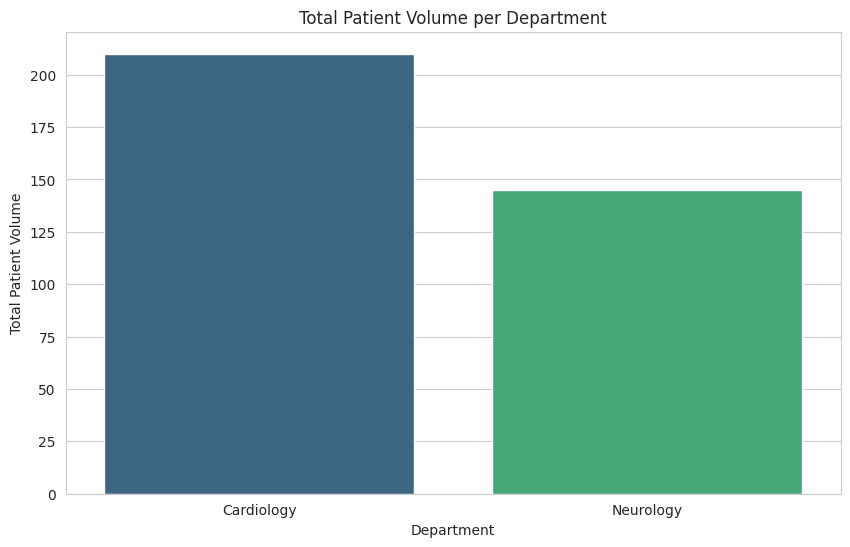

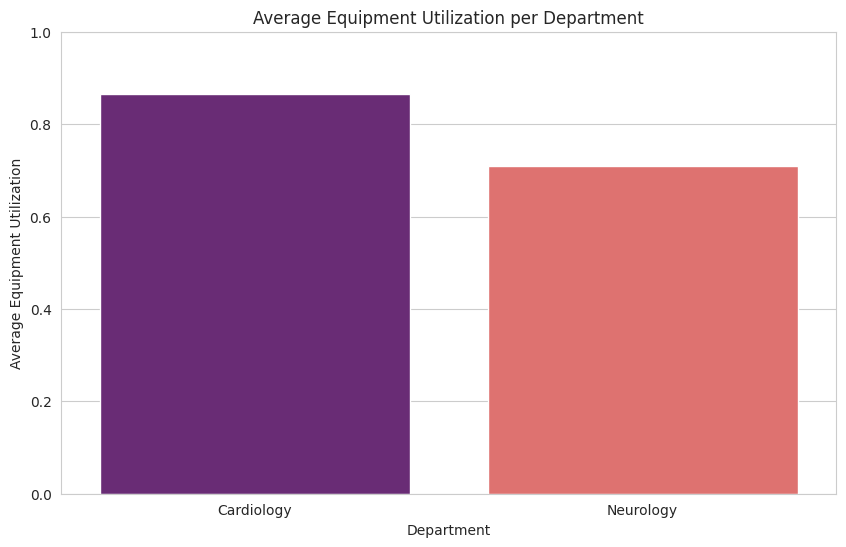

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Group by Department and sum/average relevant metrics for initial visualization
department_summary = df.groupby('Department').agg(
    Patient_Volume_Total=('Patient_Volume', 'sum'),
    Average_Treatment_Duration_Mean=('Average_Treatment_Duration', 'mean'),
    Staff_Count_Mean=('Staff_Count', 'mean'),
    Equipment_Utilisation_Mean=('Equipment_Utilisation', 'mean')
).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(x='Department', y='Patient_Volume_Total', data=department_summary, palette='viridis', hue='Department', legend=False)
plt.title('Total Patient Volume per Department')
plt.ylabel('Total Patient Volume')
plt.xlabel('Department')
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(x='Department', y='Equipment_Utilisation_Mean', data=department_summary, palette='magma', hue='Department', legend=False)
plt.title('Average Equipment Utilization per Department')
plt.ylabel('Average Equipment Utilization')
plt.xlabel('Department')
plt.ylim(0, 1) # Utilization is typically between 0 and 1
plt.show()


### 5. Calculate Resource Utilization Metrics

Now, let's calculate some key metrics as requested:
*   **Staff-to-Patient Ratios**: This will help understand the workload on staff.
*   **Resource Utilization**: We will combine patient volume and average treatment duration to estimate demand, and compare it against available staff and equipment utilization.

First, let's calculate the staff-to-patient ratio for each department.

In [5]:
# Calculate Staff-to-Patient Ratio
# For simplicity, we'll use the ratio of Staff_Count to Patient_Volume. A lower ratio might indicate higher staff workload.
df['Staff_to_Patient_Ratio'] = df['Staff_Count'] / df['Patient_Volume']

# Calculate a 'Demand' metric: Patient_Volume * Average_Treatment_Duration
df['Estimated_Demand'] = df['Patient_Volume'] * df['Average_Treatment_Duration']

# Display the new columns and updated summary statistics for these metrics
print("DataFrame with new calculated metrics:")
display(df.head())

print("\nDepartment-wise average of new metrics:")
department_resource_summary = df.groupby('Department').agg(
    Avg_Staff_to_Patient_Ratio=('Staff_to_Patient_Ratio', 'mean'),
    Avg_Estimated_Demand=('Estimated_Demand', 'mean')
).reset_index()
display(department_resource_summary)

DataFrame with new calculated metrics:


,Month,Department,Patient_Volume,Average_Treatment_Duration,Staff_Count,Equipment_Utilisation,Staff_to_Patient_Ratio,Estimated_Demand
0,2022-01-01,Cardiology,100,5,20,0.85,0.200000,500
1,2022-01-01,Neurology,70,7,15,0.70,0.214286,490
2,2022-02-01,Cardiology,110,5,21,0.88,0.190909,550
3,2022-02-01,Neurology,75,8,16,0.72,0.213333,600



Department-wise average of new metrics:


,Department,Avg_Staff_to_Patient_Ratio,Avg_Estimated_Demand
0,Cardiology,0.195455,525.0
1,Neurology,0.213810,545.0


### 6. Analysis of Resource Utilization and Demand

Now we will analyze the calculated metrics to compare demand with available capacity and identify departments with potentially high utilization.

First, let's visualize the staff-to-patient ratio and estimated demand per department.

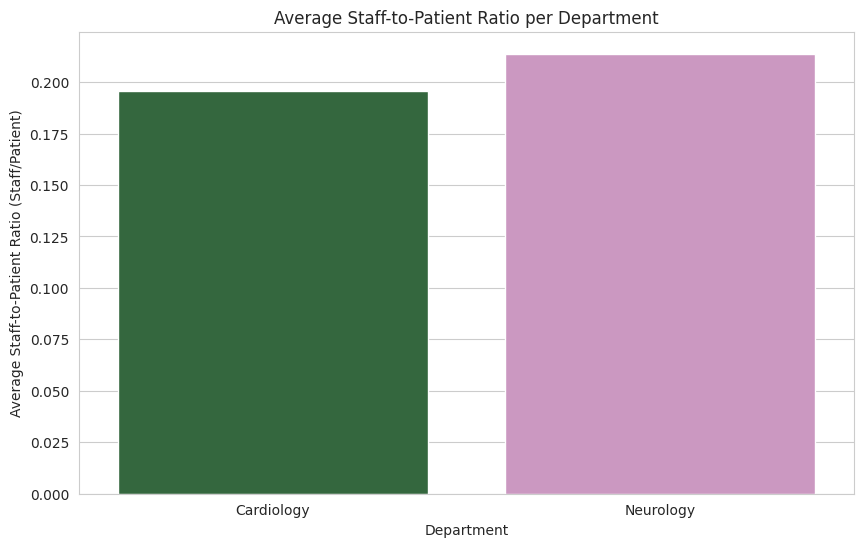

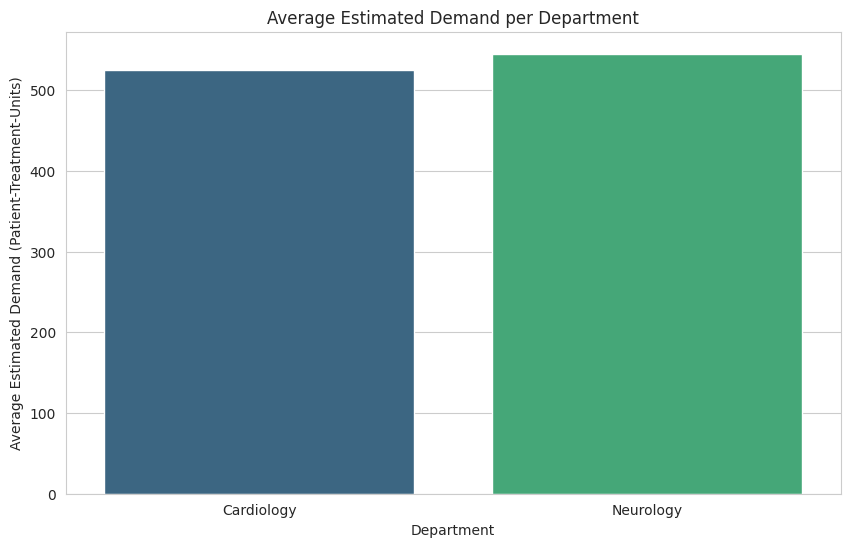

In [6]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Department', y='Avg_Staff_to_Patient_Ratio', data=department_resource_summary, palette='cubehelix', hue='Department', legend=False)
plt.title('Average Staff-to-Patient Ratio per Department')
plt.ylabel('Average Staff-to-Patient Ratio (Staff/Patient)')
plt.xlabel('Department')
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(x='Department', y='Avg_Estimated_Demand', data=department_resource_summary, palette='viridis', hue='Department', legend=False)
plt.title('Average Estimated Demand per Department')
plt.ylabel('Average Estimated Demand (Patient-Treatment-Units)')
plt.xlabel('Department')
plt.show()


### Key Insights from Current Data

Given the dummy dataset with limited data points, we can derive preliminary insights:

1.  **Patient Volume**: Cardiology has a higher total patient volume than Neurology.
2.  **Equipment Utilization**: Cardiology shows higher average equipment utilization, suggesting its resources are more heavily used.
3.  **Staff-to-Patient Ratio**: Neurology has a slightly higher staff-to-patient ratio (more staff per patient), while Cardiology has a lower ratio, which might indicate higher workload per staff member in Cardiology.
4.  **Estimated Demand**: Neurology shows a slightly higher estimated demand, likely influenced by its longer average treatment duration despite lower patient volume.

**Note:** These insights are based on a small, dummy dataset. A real-world dataset with more months of data would allow for more robust analysis, including seasonal variations and more reliable identification of consistently high utilization.

### Next Steps

With a more comprehensive dataset, the next steps would typically involve:

*   **Seasonal Variation Analysis**: Plotting monthly trends for patient volume and utilization to identify peak seasons.
*   **Statistical Significance**: Performing statistical tests (e.g., ANOVA) to determine if differences in resource utilization between departments are statistically significant.
*   **Prediction Model (Random Forest)**: Building a Random Forest model to predict a target variable (e.g., future patient volume, or an 'overload' indicator) based on historical data. However, with the current dummy data, this would not yield meaningful results.
*   **Resource Allocation Proposal**: Based on the insights, formulate a data-backed proposal for resource allocation.
